# 02 — Exploratory Data Analysis (EDA) 

In [2]:
import os
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

sys.path.append(os.path.abspath(".."))

## 1. Class Distribution & Imbalance Ratio

In [4]:
class_dist = pd.read_csv("../data/audit/class_distribution.csv")
min_c = class_dist['image_count'].min()
max_c = class_dist['image_count'].max()
median_c = class_dist['image_count'].median()
imbalance_ratio = max_c / min_c
majority_baseline = (max_c / class_dist['image_count'].sum()) * 100

print(f"Fewest samples (Minority class): {min_c} ({class_dist.loc[class_dist['image_count'].idxmin(), 'class_name']})")
print(f"Most samples (Majority class): {max_c} ({class_dist.loc[class_dist['image_count'].idxmax(), 'class_name']})")
print(f"Median: {median_c}")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}x")
print(f"Majority Class Baseline: {majority_baseline:.2f}%")

Fewest samples (Minority class): 152 (Potato___healthy)
Most samples (Majority class): 5507 (Orange___Haunglongbing_(Citrus_greening))
Median: 1092.5
Imbalance Ratio: 36.23x
Majority Class Baseline: 10.14%


## 2. Class and Plant Species Distribution

Visualizing the dataset to understand the distribution of samples across individual diseases and overarching plant species:
- **Class Distribution**: A detailed breakdown of all 38 classes to visually identify the minority and majority classes.
- **Species Distribution**: Aggregates the image counts by plant species (extracted from the `Species___Disease` naming convention) to show which plants have the most representation in the dataset.

/tmp/ipykernel_31849/71097096.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


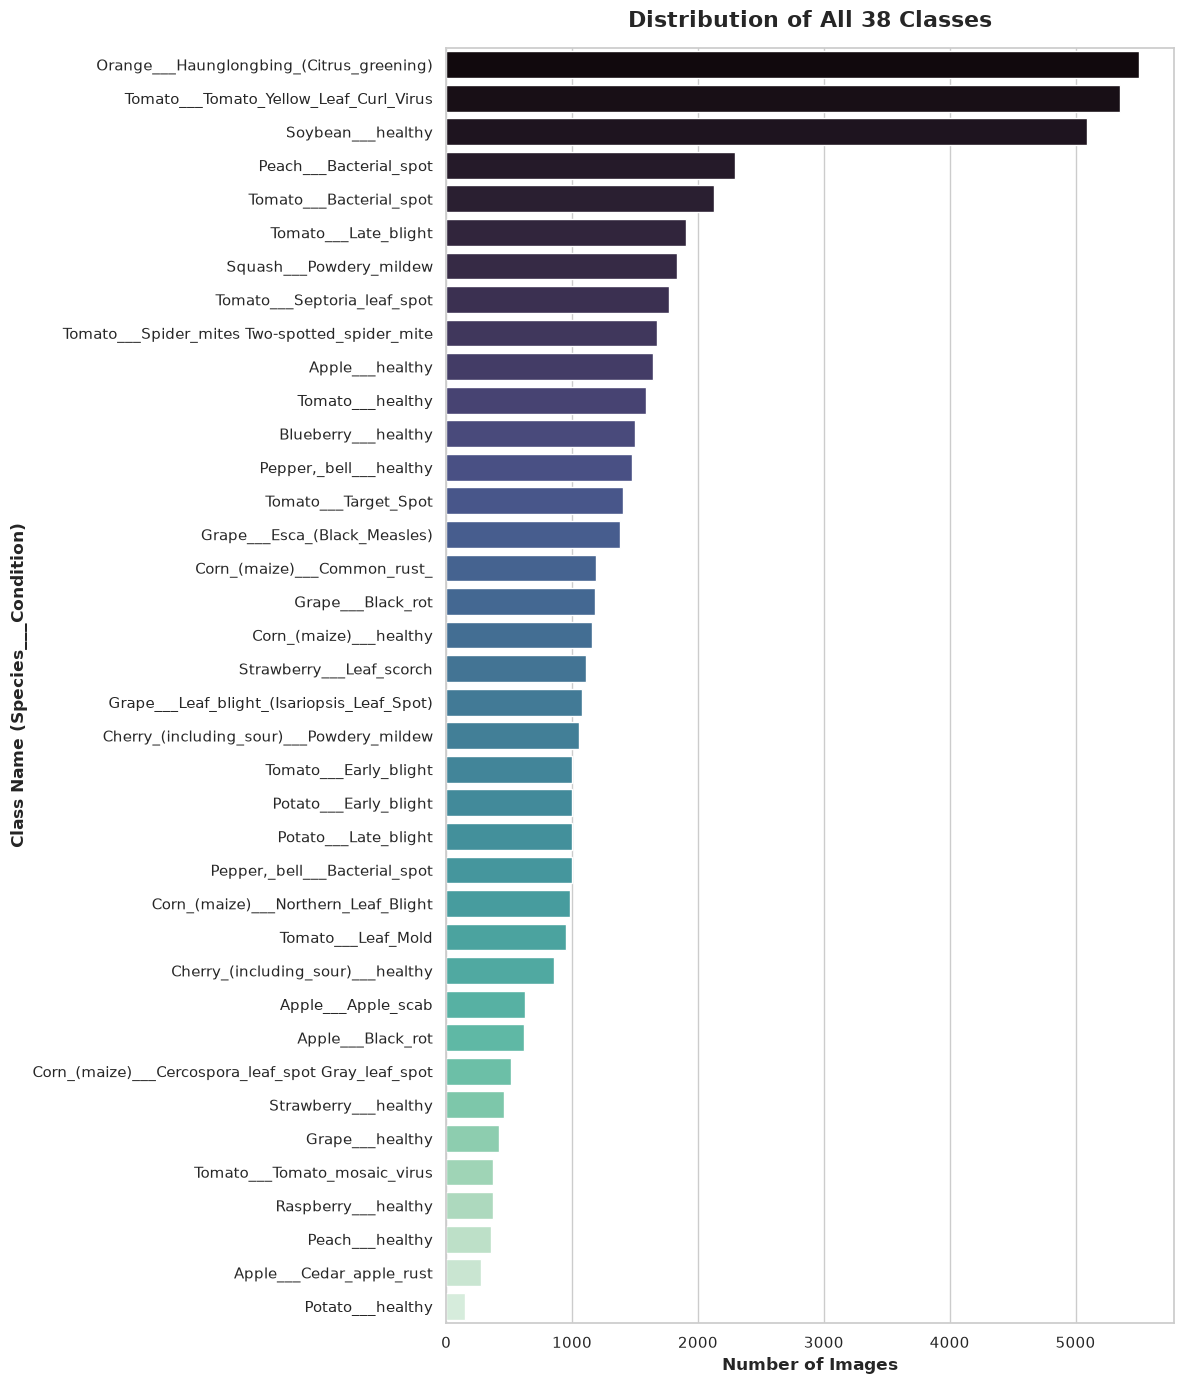

Saved Class Distribution plot to: ../outputs/figures/class_distribution.png



/tmp/ipykernel_31849/71097096.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


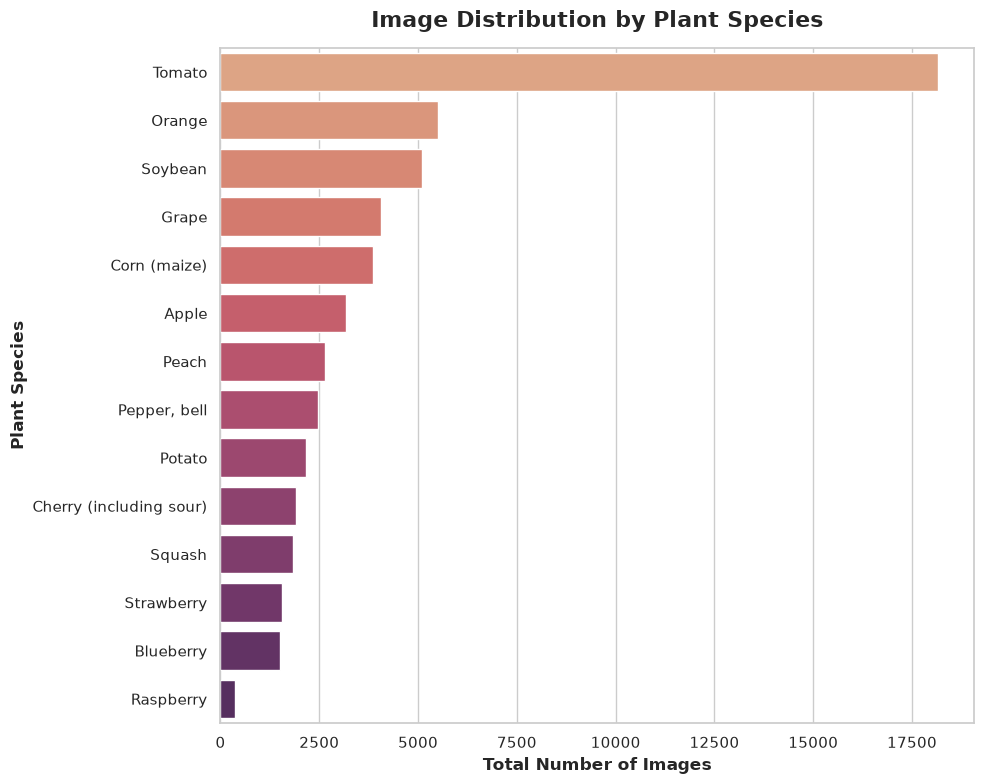

Saved Species Distribution plot to: ../outputs/figures/species_distribution.png


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Initialize output directory for figures
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Set Seaborn visual theme
sns.set_theme(style="whitegrid")

# 2. Data Preparation
# Extract species name from the class_name (Format: "Species___Disease")
class_dist['species'] = class_dist['class_name'].apply(lambda x: x.split('___')[0].replace('_', ' '))

# Aggregate counts by species and sort
species_dist = class_dist.groupby('species')['image_count'].sum().reset_index()
species_dist = species_dist.sort_values(by='image_count', ascending=False)

# Sort the main class distribution
class_dist_sorted = class_dist.sort_values(by='image_count', ascending=False)


# ==========================================
# PLOT 1: DISTRIBUTION OF ALL 38 CLASSES
# ==========================================
plt.figure(figsize=(12, 14)) # Tall figure to accommodate 38 labels
sns.barplot(
    data=class_dist_sorted,
    x='image_count', 
    y='class_name',
    palette='mako'
)
plt.title('Distribution of All 38 Classes', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Number of Images', fontsize=12, fontweight='bold')
plt.ylabel('Class Name (Species___Condition)', fontsize=12, fontweight='bold')
plt.tight_layout()

# Save Plot 1
class_save_path = figures_dir / "class_distribution.png"
plt.savefig(class_save_path, dpi=300, bbox_inches='tight')
plt.show() 
print(f"Saved Class Distribution plot to: {class_save_path}\n")


# ==========================================
# PLOT 2: AGGREGATED SPECIES DISTRIBUTION
# ==========================================
plt.figure(figsize=(10, 8)) # Standard aspect ratio for fewer categories
sns.barplot(
    data=species_dist,
    x='image_count',
    y='species',
    palette='flare'
)
plt.title('Image Distribution by Plant Species', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Total Number of Images', fontsize=12, fontweight='bold')
plt.ylabel('Plant Species', fontsize=12, fontweight='bold')
plt.tight_layout()

# Save Plot 2
species_save_path = figures_dir / "species_distribution.png"
plt.savefig(species_save_path, dpi=300, bbox_inches='tight')
plt.show() 
print(f"Saved Species Distribution plot to: {species_save_path}")

## 3. Sample Image Grid (38 Classes)

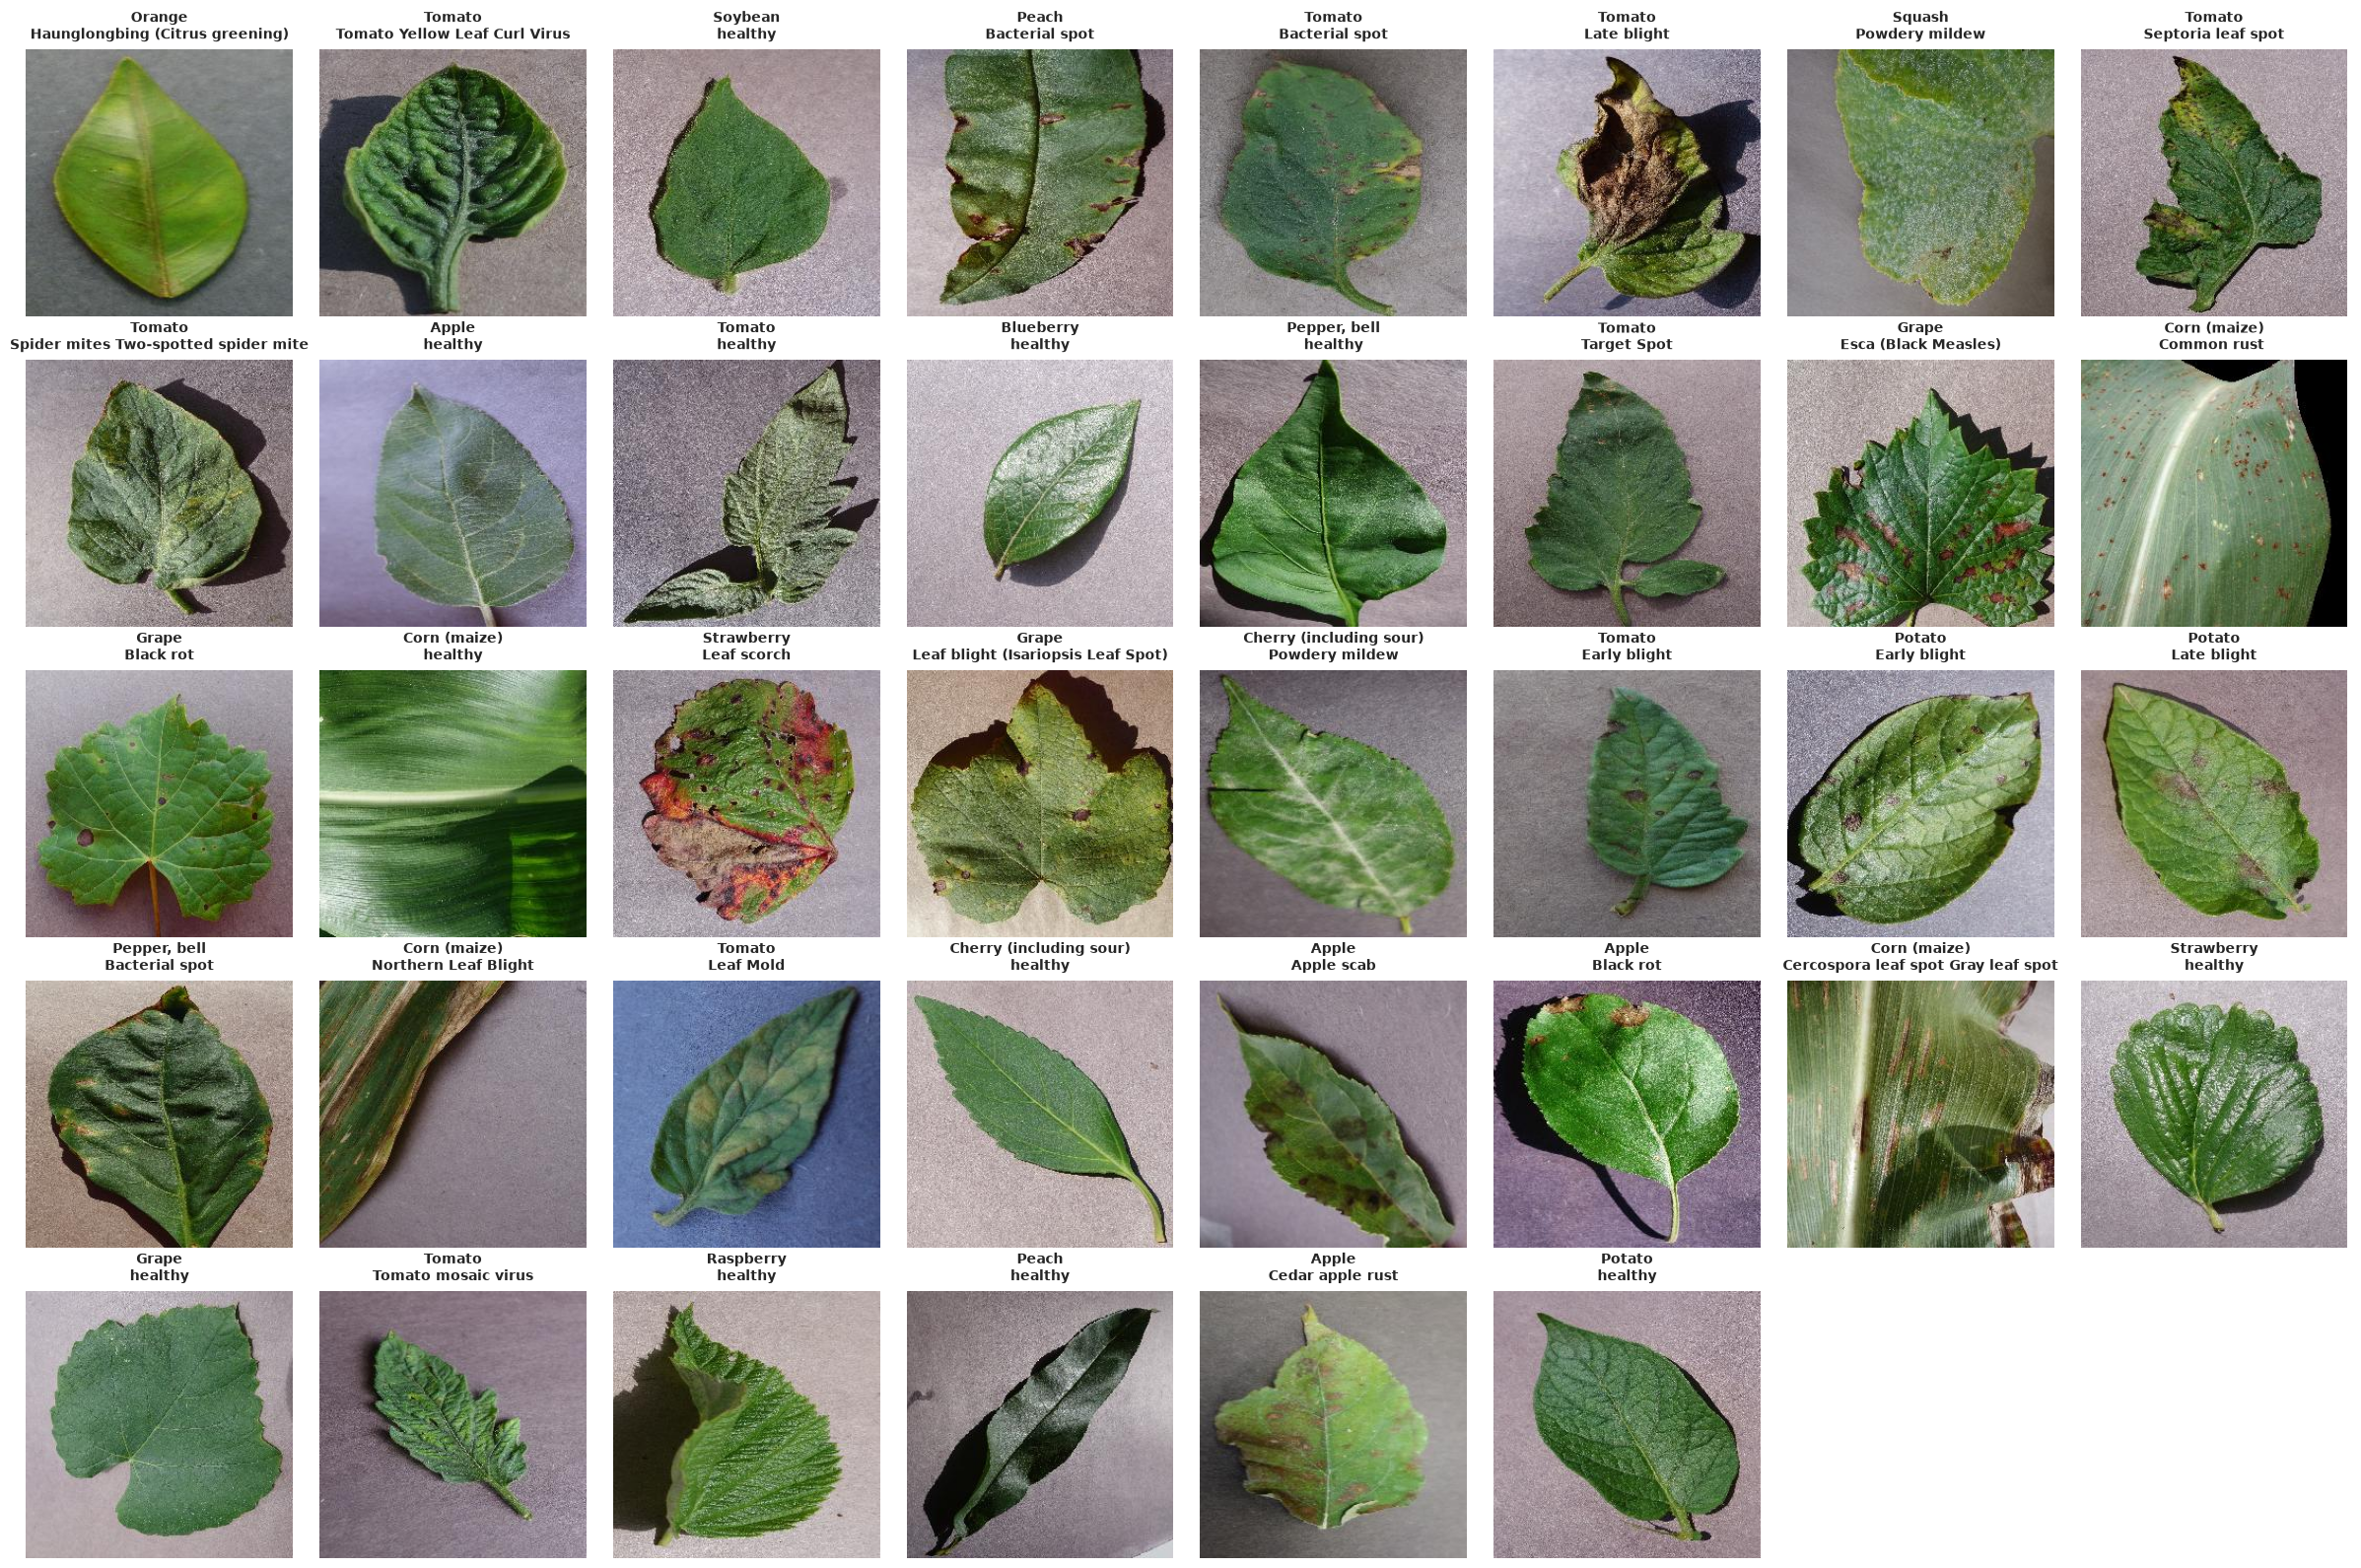

Saved sample image grid to: ../outputs/figures/38_classes_sample_grid.png


In [8]:
import math
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# 1. Ensure the output directory exists
figures_dir = Path("../outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# 2. Locate the color data directory
# Adjust the base path if your data is located elsewhere
data_raw_dir = Path("../data/raw")
color_candidates = list(data_raw_dir.rglob("color"))
if not color_candidates:
    raise FileNotFoundError(f"Could not find 'color' directory in {data_raw_dir}")
color_dir = next(p for p in color_candidates if p.is_dir())

# Get the list of all 38 classes from the previously loaded class_dist dataframe
classes = class_dist['class_name'].tolist()
num_classes = len(classes)

# 3. Define grid dimensions (e.g., 8 columns x 5 rows = 40 slots for 38 classes)
cols = 8
rows = math.ceil(num_classes / cols)

# Create the figure
fig, axes = plt.subplots(rows, cols, figsize=(24, 16))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

# 4. Populate the grid
for i, cls_name in enumerate(classes):
    cls_dir = color_dir / cls_name
    
    # Grab all valid images in the class directory
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    images = [p for p in cls_dir.iterdir() if p.suffix.lower() in valid_exts]
    
    if images:
        # Pick one random image
        sample_img_path = random.choice(images)
        img = Image.open(sample_img_path)
        
        # Display image
        axes[i].imshow(img)
        
        # Format the title: replace '___' with a newline to prevent overlap
        formatted_title = cls_name.replace("___", "\n").replace("_", " ")
        axes[i].set_title(formatted_title, fontsize=10, fontweight='bold', pad=8)
    
    # Hide the axis ticks and borders for a cleaner look
    axes[i].axis('off')

# 5. Turn off any remaining empty subplots (since 40 slots > 38 classes)
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

# Adjust spacing between subplots
plt.tight_layout()

# 6. Save and show the figure
grid_save_path = figures_dir / "38_classes_sample_grid.png"
plt.savefig(grid_save_path, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Saved sample image grid to: {grid_save_path}")

## 4. Exact and Perceptual Near-Duplicate Report

Identifying duplicate images is crucial to prevent **data leakage** (having the same image in both training and validation sets, which artificially inflates model performance).
- **Exact Duplicates**: Detected using **MD5 hashing** on the file bytes. Finds files that are identical at the byte level.
- **Perceptual Near-Duplicates**: Detected using **Perceptual Hashing (pHash)**. Finds images that look identical to the human eye but might have different resolutions, compression artifacts, or file formats.

In [9]:
import hashlib
import imagehash
import pandas as pd
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm
from collections import defaultdict

# 1. Setup paths
audit_dir = Path("../data/audit")
audit_dir.mkdir(parents=True, exist_ok=True)

data_raw_dir = Path("../data/raw")
color_candidates = list(data_raw_dir.rglob("color"))
if not color_candidates:
    raise FileNotFoundError(f"Could not find 'color' directory in {data_raw_dir}")
color_dir = next(p for p in color_candidates if p.is_dir())

# 2. Gather all images
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = [p for p in color_dir.rglob("*") if p.is_file() and p.suffix.lower() in valid_exts]

print(f"Scanning {len(image_paths):,} images for duplicates...")

# Dictionaries to store hashes mapping to lists of file paths
md5_dict = defaultdict(list)
phash_dict = defaultdict(list)
corrupt_files = []

# 3. Compute Hashes (This may take a few minutes for 50k+ images)
for img_path in tqdm(image_paths, desc="Computing Hashes"):
    try:
        # Calculate MD5 (Exact Duplicate)
        with open(img_path, 'rb') as f:
            file_bytes = f.read()
            md5_hash = hashlib.md5(file_bytes).hexdigest()
            md5_dict[md5_hash].append(str(img_path.relative_to(color_dir.parent)))
            
        # Calculate pHash (Perceptual Near-Duplicate)
        with Image.open(img_path) as img:
            p_hash = str(imagehash.phash(img))
            phash_dict[p_hash].append(str(img_path.relative_to(color_dir.parent)))
            
    except Exception as e:
        corrupt_files.append((str(img_path), str(e)))

# 4. Filter hashes that have more than 1 associated image
exact_duplicates = {h: paths for h, paths in md5_dict.items() if len(paths) > 1}
near_duplicates = {h: paths for h, paths in phash_dict.items() if len(paths) > 1}

# 5. Format results into DataFrames for easy exporting and viewing
def format_duplicates(dup_dict, hash_type):
    records = []
    for h, paths in dup_dict.items():
        for path in paths:
            records.append({"hash": h, "hash_type": hash_type, "file_path": path})
    return pd.DataFrame(records)

df_exact = format_duplicates(exact_duplicates, "MD5 (Exact)")
df_near = format_duplicates(near_duplicates, "pHash (Near)")

# Combine and save report
df_all_dups = pd.concat([df_exact, df_near], ignore_index=True)
dup_report_path = audit_dir / "duplicate_images_report.csv"

if not df_all_dups.empty:
    df_all_dups.to_csv(dup_report_path, index=False)

# 6. Print Summary
print("\n" + "=" * 50)
print("               DUPLICATE AUDIT SUMMARY               ")
print("=" * 50)
print(f"Exact duplicates (MD5) found    : {len(exact_duplicates)} groups")
print(f"Near-duplicates (pHash) found   : {len(near_duplicates)} groups")

if not df_all_dups.empty:
    total_redundant = len(df_all_dups) - (len(exact_duplicates) + len(near_duplicates))
    print(f"Total redundant files to remove : ~{total_redundant} files")
    print(f"\nDetailed report saved to: {dup_report_path}")
    
    # Show a sneak peek of the first near-duplicate group
    if near_duplicates:
        print("\nExample of a Near-Duplicate group:")
        first_group = list(near_duplicates.values())[0]
        for path in first_group:
            print(f" - {path}")
else:
    print("\nGreat news! No duplicates or near-duplicates found in the dataset.")

/home/tanthanh/Documents/Projects/PlantDiseaseClassification/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Scanning 54,305 images for duplicates...


Computing Hashes: 100%|██████████| 54305/54305 [00:47<00:00, 1144.85it/s]


               DUPLICATE AUDIT SUMMARY               
Exact duplicates (MD5) found    : 21 groups
Near-duplicates (pHash) found   : 22 groups
Total redundant files to remove : ~43 files

Detailed report saved to: ../data/audit/duplicate_images_report.csv

Example of a Near-Duplicate group:
 - color/Apple___healthy/11beda66-01e9-4bfd-be37-c0f8646d1478___RS_HL 6271.JPG
 - color/Apple___healthy/13298d36-4425-437d-ae8e-c7d70e200084___RS_HL 6271.JPG
